In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [5]:
df = pd.read_csv(r"D:\ML Projects\Unsupervised practice\IRIS unsupervised.csv")
df.info()
df.head(5)


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


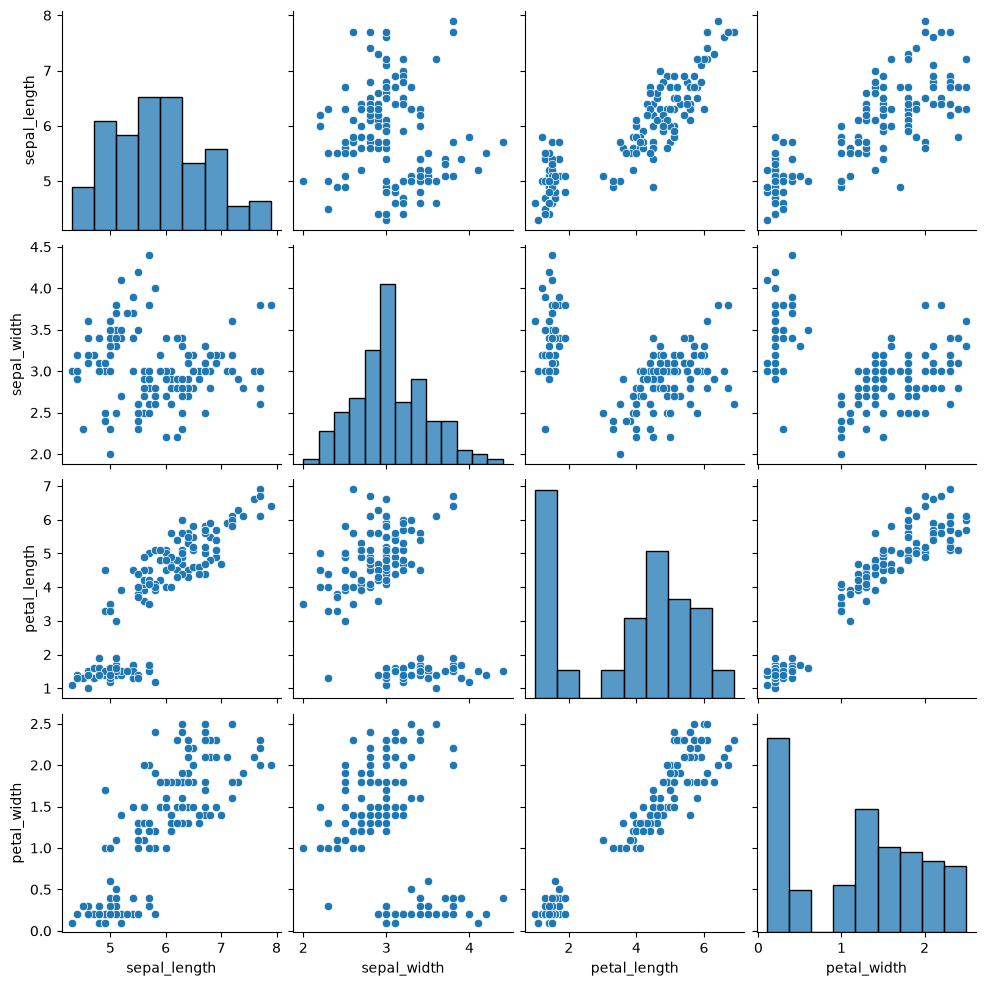

In [6]:
sns.pairplot(data=df)
plt.show()


In [7]:
from sklearn.cluster import KMeans
wcss = []
for i in range (2,21):
    km = KMeans(n_clusters=i, init='k-means++')
    km.fit(df)
    wcss.append(km.inertia_)    #Wcss value

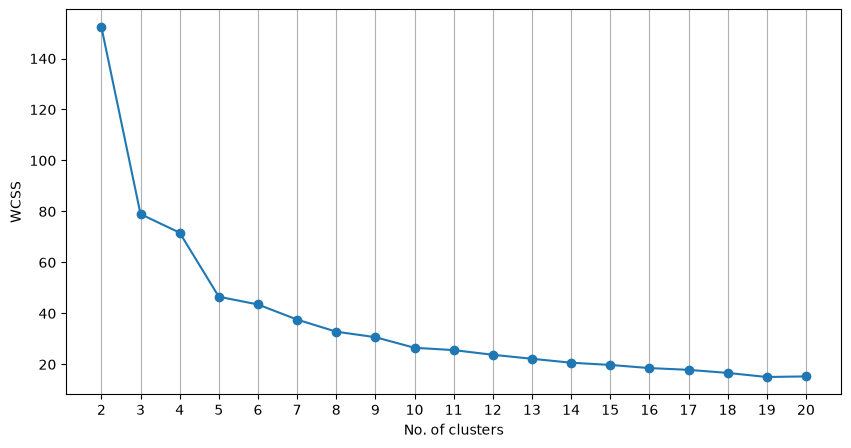

In [8]:
plt.figure(figsize=(10,5))
plt.plot([i for i in range(2,21)], wcss, marker = 'o')
plt.xlabel('No. of clusters')
plt.ylabel('WCSS')
plt.xticks([i for i in range(2,21)])
plt.grid(axis='x')
plt.show()

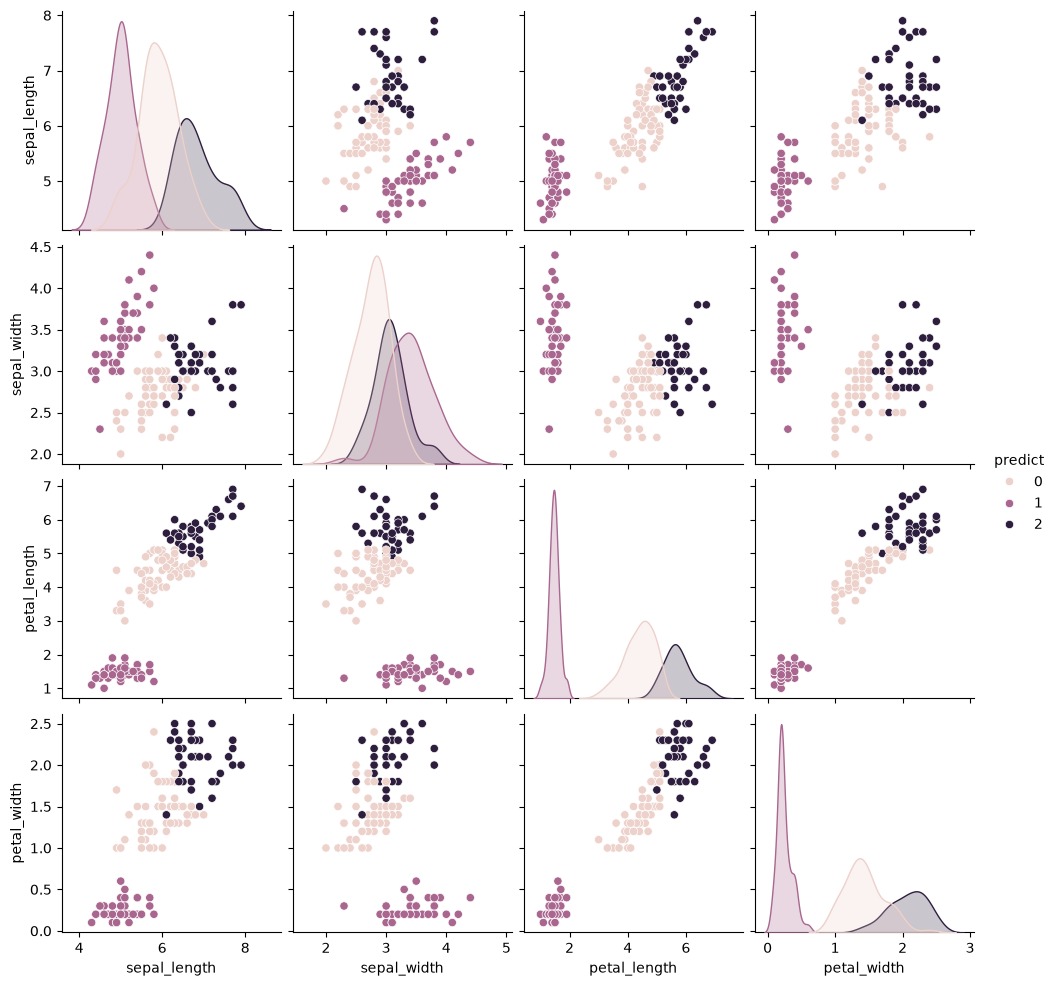

In [9]:

kmn = KMeans(n_clusters=3)
x = df[['sepal_length', 'sepal_width',
        'petal_length', 'petal_width']]
lables = kmn.fit_predict(x)
df['predict'] = lables

sns.pairplot(data=df, hue='predict')
plt.show()

In [14]:
x = df.drop(columns=['predict'])
# we're dropping predict column as it will assumed while calculating silhoutte score

from sklearn.metrics import silhouette_score

ss = []  #to store silhoutte score
c_no = [j for j in range(2,22)]   #To store no. of clusters

for i in range (2,22):
    km1 = KMeans(n_clusters=i)
    km1.fit(df)
    ss.append(silhouette_score(x,km1.labels_))

print(pd.DataFrame(ss))


           0
0   0.680814
1   0.552592
2   0.485248
3   0.361432
4   0.458750
5   0.438875
6   0.316461
7   0.344482
8   0.319942
9   0.292718
10  0.302431
11  0.277020
12  0.278098
13  0.285916
14  0.286876
15  0.251866
16  0.247819
17  0.267864
18  0.285107
19  0.266655


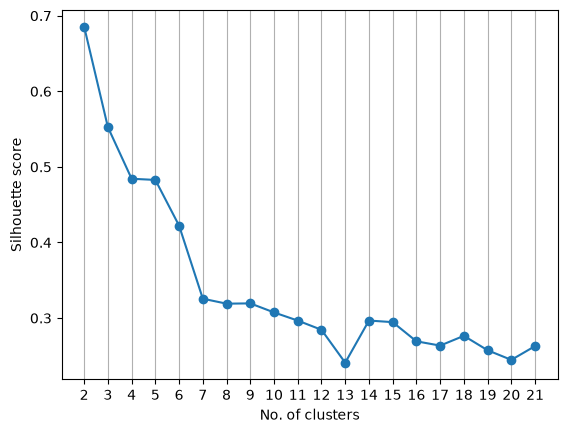

In [ ]:
plt.plot(c_no,ss,marker='o')
plt.xlabel('No. of clusters')
plt.ylabel('Silhouette score')
plt.xticks(c_no)
plt.grid(axis='x')
plt.show()

# Accordind to silhoutte score best o. of clusters are 2 but as per wcss it's 3
# Reason is in graph we normally able to see 2 clusters only

Hierrarchical Clustering

In [ ]:
df1 = pd.read_csv(r"D:\Practice Dataset\Unsupervised practice\IRIS unsupervised.csv")
df1.info()
df1.head(5)
dataset_copy = df1.copy()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


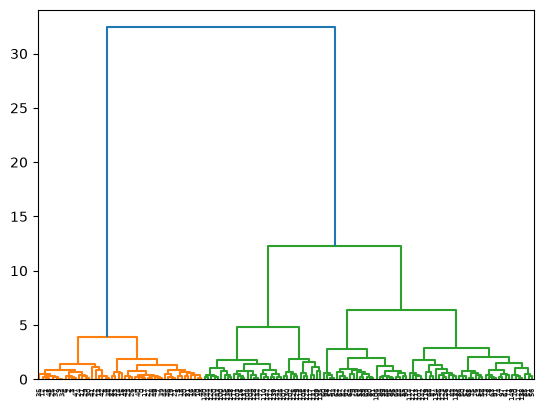

<Figure size 2000x1000 with 0 Axes>

In [ ]:
import scipy.cluster.hierarchy as hc

hc.dendrogram(hc.linkage(df1,method='ward'))
plt.figure(figsize=(20,10))
plt.savefig("dendogram.png")
plt.show()

#"We draw a horizontal line through the dendrogram and count how many vertical branches it intersects. 
# That gives us the number of clusters."
# so no. of clusters are 2

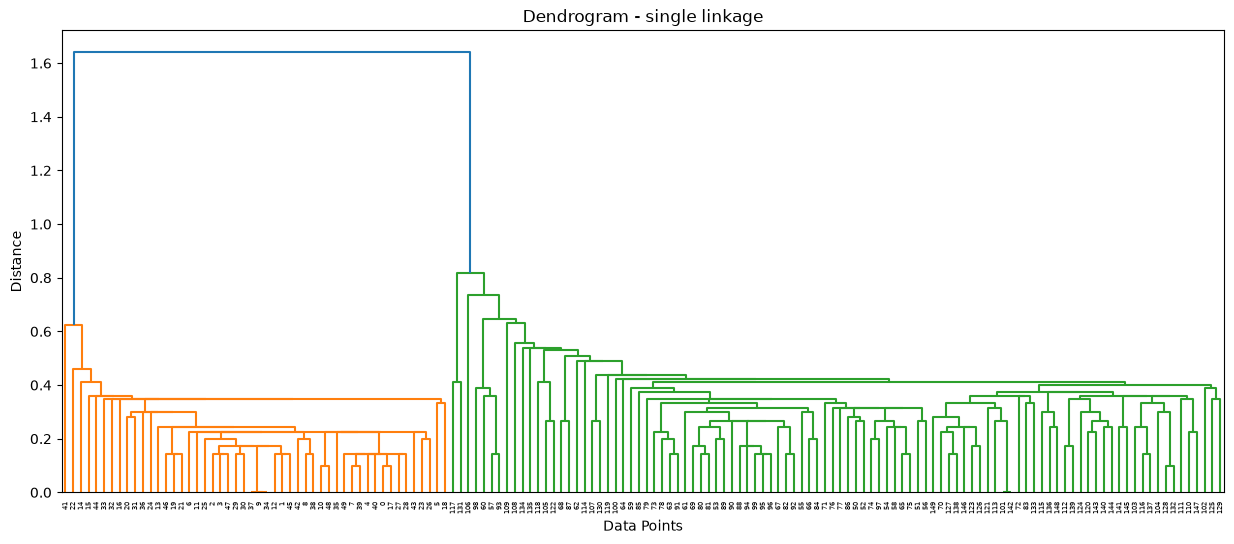

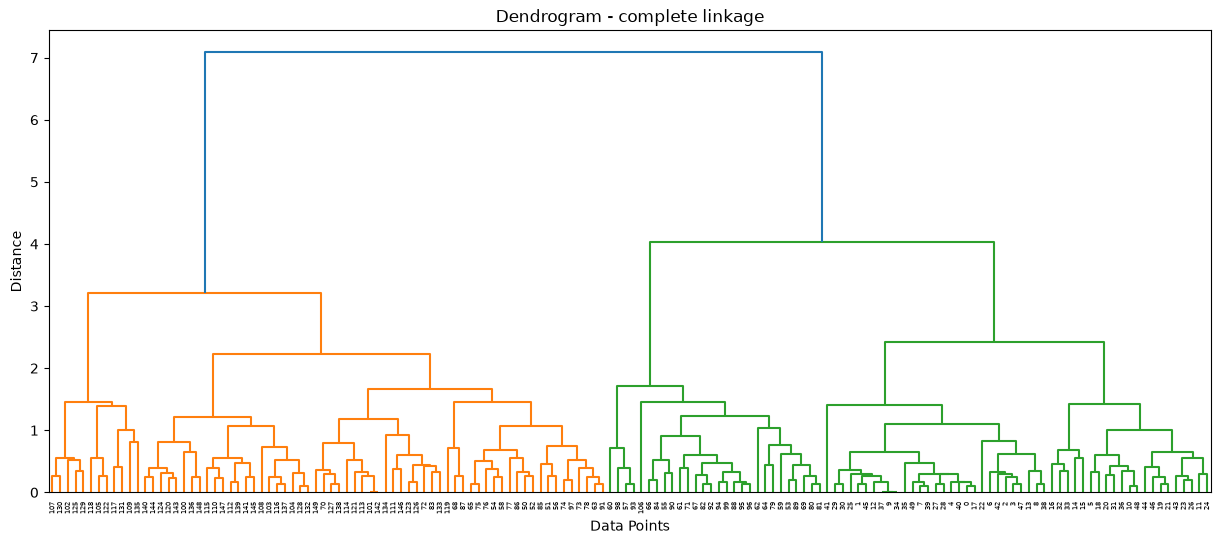

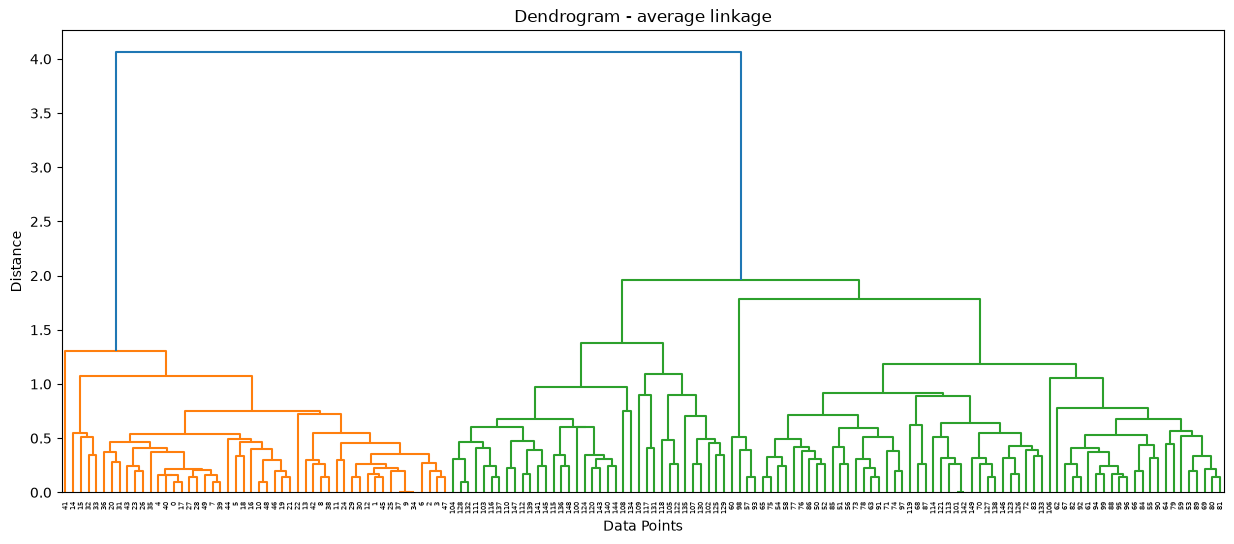

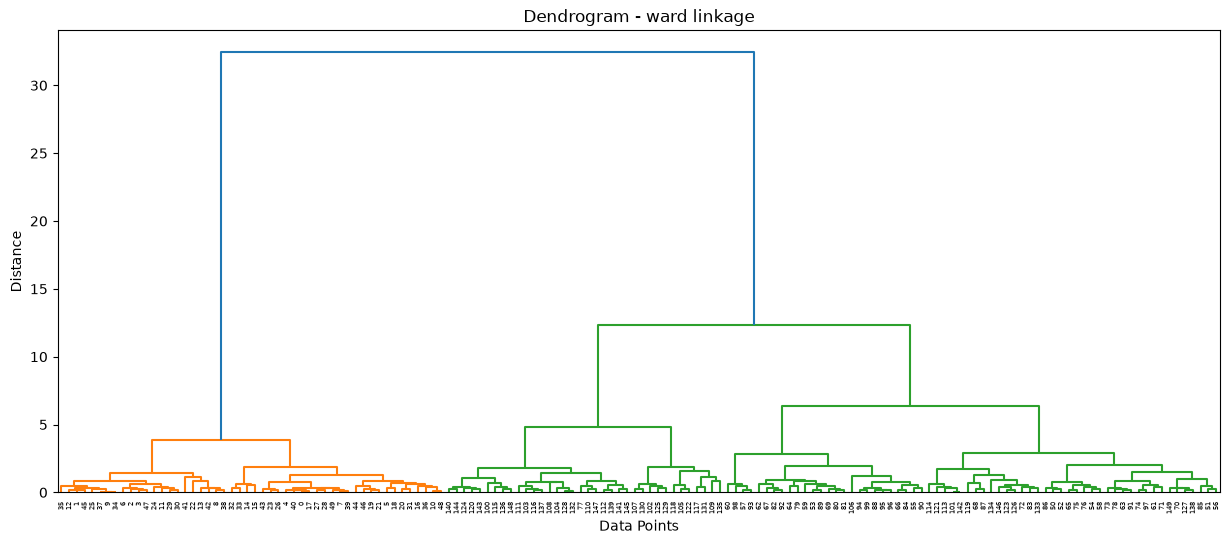

In [ ]:
methods = ['single', 'complete', 'average', 'ward']

for method in methods:
    plt.figure(figsize=(15, 6))
    hc.dendrogram(hc.linkage(dataset_copy, method=method))
    plt.title(f'Dendrogram - {method} linkage')
    plt.xlabel('Data Points')
    plt.ylabel('Distance')
    plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering
ac = AgglomerativeClustering(n_clusters=2,linkage='single')
labels = ac.fit_predict(df1)
# first values stored in variable then converted into column of dataframe
df1['predict'] = labels
# New column has been created for predicted column


In [ ]:
# To see best silhouette score
ss1 = []
for i in range(2,21):
    ac = AgglomerativeClustering(n_clusters=i,linkage='single')
    labels2 = ac.fit_predict(dataset_copy)
    ss1.append(silhouette_score(dataset_copy,labels2))

score = silhouette_score(dataset_copy,labels)
print(score)

0.6863930543445408


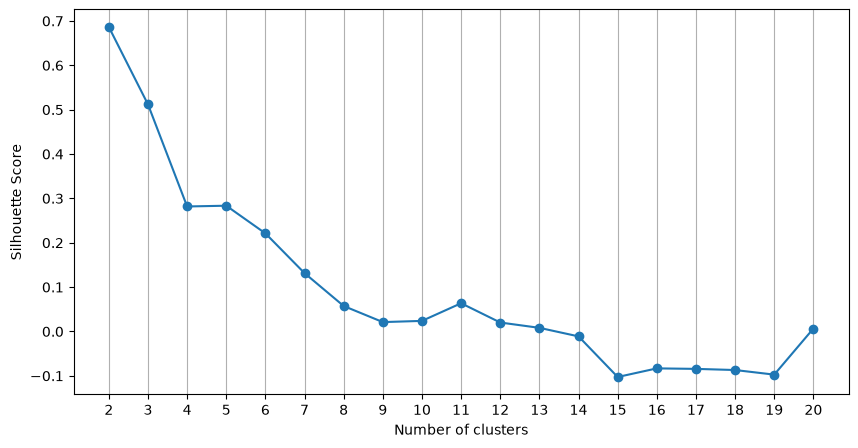

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(range(2, 21), ss1, marker='o')

plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 21))
plt.grid(axis='x')

plt.show()

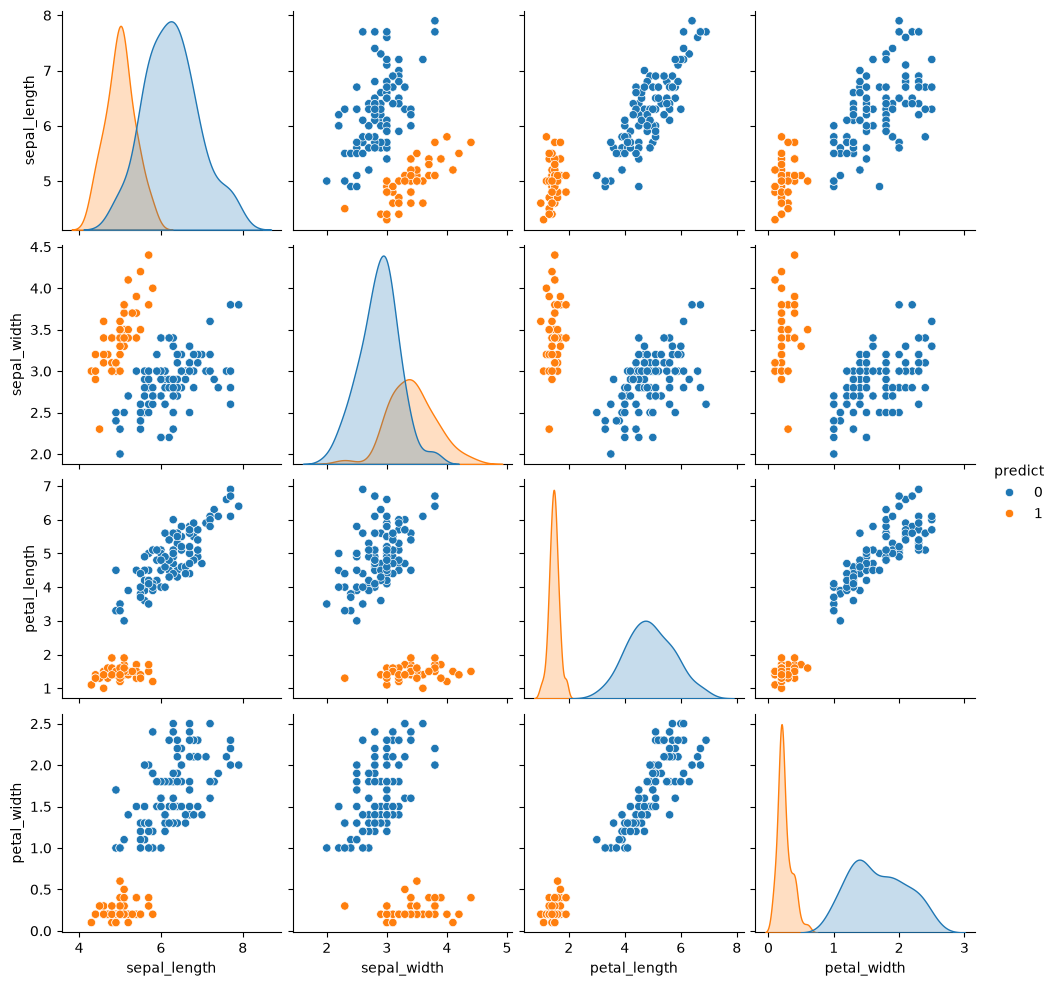

In [ ]:
#to see clustering
sns.pairplot(data=df1, hue='predict')
plt.show()

# Another way


In [ ]:
iris_data = pd.read_csv(r"D:\Practice Dataset\Unsupervised practice\IRIS unsupervised.csv")

iris_data_copy = iris_data.copy()

iris_data.head()

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [ ]:
iris_data.info()
iris_data.isnull().sum()
iris_data.describe()


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [ ]:
from sklearn.cluster import AgglomerativeClustering
import scipy.cluster.hierarchy as hc
ac = AgglomerativeClustering()
methods= ['ward', 'complete', 'average', 'single']

# for dendogram of all linnkage method
for m in methods:
    plt.figure(figsize=(25,10))
    hc.dendrogram(hc.linkage(iris_data_copy,method=m))
    plt.title(f"{m} linkage")
    plt.xlabel('Data points')
    plt.ylabel('Distance')
    plt.show()

In [ ]:
# From the dendrograms, Ward and Complete linkage showed a clear separation suggesting approximately 3 clusters.
# I therefore selected K=3 as a candidate and used the Silhouette Score to compare the linkage methods.

from sklearn.metrics import silhouette_score

for m in methods:
    ac = AgglomerativeClustering(n_clusters=3,linkage=m)
    
    labels_for_3 = ac.fit_predict(iris_data)

    score = silhouette_score(iris_data,labels_for_3)

    print(f"{m} -> {score}")


ward -> 0.5540972908150553
complete -> 0.5133502348448076
average -> 0.5539343898551252
single -> 0.5118387098922373


In [ ]:
#calculate score for upto 15 clusters with all method
result = []
for m in methods:
    
    for k in range(2,10):
        ac = AgglomerativeClustering(n_clusters=k,linkage=m)

        labels_with_all = ac.fit_predict(iris_data)

        score = silhouette_score(iris_data,labels_with_all)

        result.append({'Linkage':m,
                           'Clusters':k,
                           'Score':score})

result_df = pd.DataFrame(result)
#print(result_df)
        
#To find best result
best_result = result_df.loc[result_df["Score"].idxmax()]
print(best_result)


Linkage        ward
Clusters          2
Score       0.69833
Name: 0, dtype: object


In [ ]:
# The dendrogram suggested that 3 clusters could be a reasonable choice. 
# However, after evaluating different linkage methods and cluster numbers using the Silhouette Score, 
# Ward linkage with 2 clusters achieved the highest score of 0.686393.
# Therefore, based on the Silhouette Score, Ward linkage with 2 clusters is the optimal configuration among the tested combinations.
final_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

final_labels = final_model.fit_predict(iris_data)

iris_data["cluster"] = final_labels

# DBSCAN

In [ ]:
dbscan_data = pd.read_csv(r"D:\Practice Dataset\Unsupervised practice\IRIS unsupervised.csv")
dbscan_data_copy = dbscan_data.copy()